# EDA baches (bachómetro) vs. red hidrográfica

Los baches ya traen `colonia_id` resuelto espacialmente (job `add_colonia_bache_with_gpkg`: within + nearest <=500 m). Se unen al sector por `colonia_id` igual que en las libretas 06-07.

In [30]:
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from project_name.text import normalize_name

In [31]:
DATA = Path("../../data/processed")
EXPERIMENT = Path("notebook_experimentation_data")

baches = pd.read_csv(DATA / "bachometro/baches_hermosillo_colonia_filled.csv")
sectores = pd.read_csv(EXPERIMENT / "colonias_hermosillo.csv", usecols=["colonia_id", "sector"], dtype={"colonia_id": str})
colonias = gpd.read_file(DATA / "aguah/colonias_hermosillo.gpkg")

baches["date"] = pd.to_datetime(baches["date"], errors="coerce")
baches["mes"] = baches["date"].dt.month
baches["anio"] = baches["date"].dt.year
print(f"{len(baches)} baches | "
      f"{baches['date'].min().date()} -> {baches['date'].max().date()}")
print(baches["contexto_ubicacion"].value_counts().to_string())

38975 baches | 2021-09-17 -> 2026-09-24
contexto_ubicacion
dentro_asentamiento                34988
cerca_asentamiento                  3476
probable_carretera_o_zona_rural      511


## Union por colonia

El `colonia_id` del bache resuelve su sector; los ~600 puntos sin colonia (probable carretera / zona rural) quedan fuera del analisis por sector, consistente con excluir lo que esta fuera de la ciudad.

In [32]:
# area por sector desde las colonias de la ciudad (mismo patron que nb07)
METRICO = 6372
colonias_ciudad = colonias[colonias["locality_code"] == "0001"].to_crs(METRICO)
colonias_ciudad["colonia_id"] = colonias_ciudad["colonia_id"].astype("Int64")
sectores_num = sectores.assign(colonia_id=sectores["colonia_id"].astype("Int64"))
colonias_ciudad = colonias_ciudad.merge(sectores_num, on="colonia_id", how="left")
sector_area = (
    colonias_ciudad.dropna(subset=["sector"])
    .groupby("sector")
    .agg(area_km2=("geometry", lambda g: g.area.sum() / 1e6),
         colonias=("sector", "size"))
)

# sector al bache por colonia_id (float en el csv -> Int64 para que empareje)
baches["colonia_id"] = baches["colonia_id"].astype("Int64")
baches = baches.merge(sectores_num, on="colonia_id", how="left")
con_sector = baches.dropna(subset=["sector"])
print(f"{len(con_sector)} / {len(baches)} baches con sector "
      f"({baches['colonia_id'].nunique()} colonias)")
print(sector_area.round(1).to_string())

38209 / 38975 baches con sector (679 colonias)
        area_km2  colonias
sector                    
Centro      36.9       178
Norte       55.6       398
Sur         40.0       186


## Baches por km2 por mes

Eje x: mes del año (todos los años 2021-2026 agrupados). Nota: 2021 empieza en septiembre y 2026 es parcial - el agrupado por mes diluye los años incompletos.

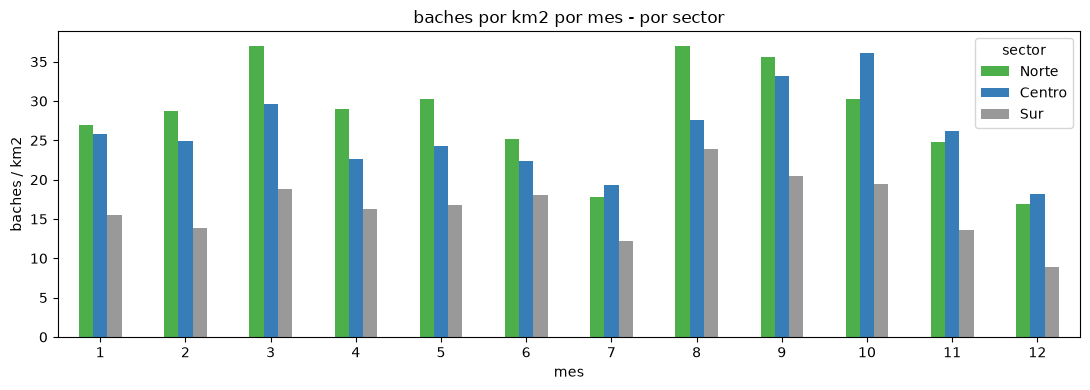

In [33]:
orden_sectores = ["Norte", "Centro", "Sur"]
mes_sector = (
    con_sector.groupby(["mes", "sector"]).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)

(mes_sector / sector_area["area_km2"]).reindex(
    columns=orden_sectores
).plot.bar(
    figsize=(11, 4), rot=0,
    color=["#4daf4a", "#377eb8", "#999999"],
)
plt.xlabel("mes")
plt.ylabel("baches / km2")
plt.title("baches por km2 por mes - por sector")
plt.legend(title="sector")
plt.tight_layout()
plt.show()

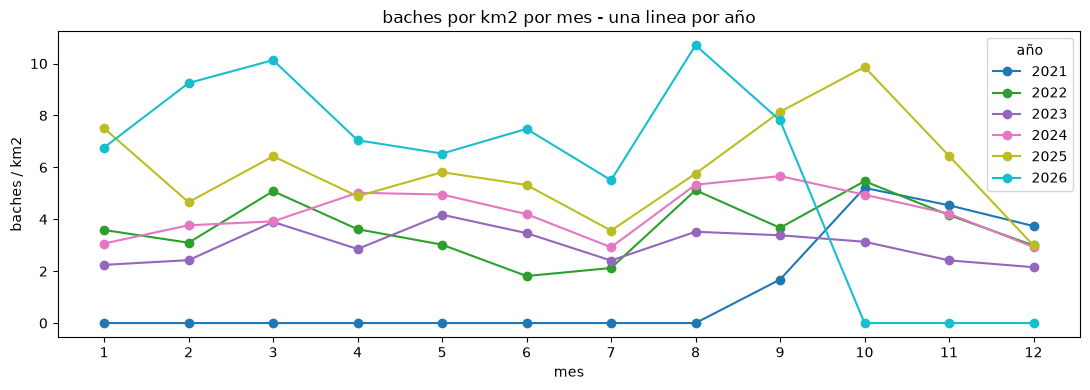

In [34]:
# baches por km2 por mes, una linea por año - buscar temporadas con mas reportes
# 2021 solo tiene sep-dic y 2026 va hasta sep (años parciales)
mes_anio = (
    con_sector.groupby(["mes", "anio"]).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)
(mes_anio / sector_area["area_km2"].sum()).plot(
    figsize=(11, 4), marker="o", colormap="tab10"
)
plt.xlabel("mes")
plt.ylabel("baches / km2")
plt.title("baches por km2 por mes - una linea por año")
plt.xticks(range(1, 13))
plt.legend(title="año")
plt.tight_layout()
plt.show()

**Lectura:** (a rellenar tras ver la grafica - ¿los baches tambien concentran en jul-sep como las llamadas de superficie?)

## Mapa: baches vs. red hidrografica

Colonias coloreadas por sector, la red  y cuerpos de agua  (recortadas a la ciudad + 1 km de margen) y los puntos de bache georreferenciados.

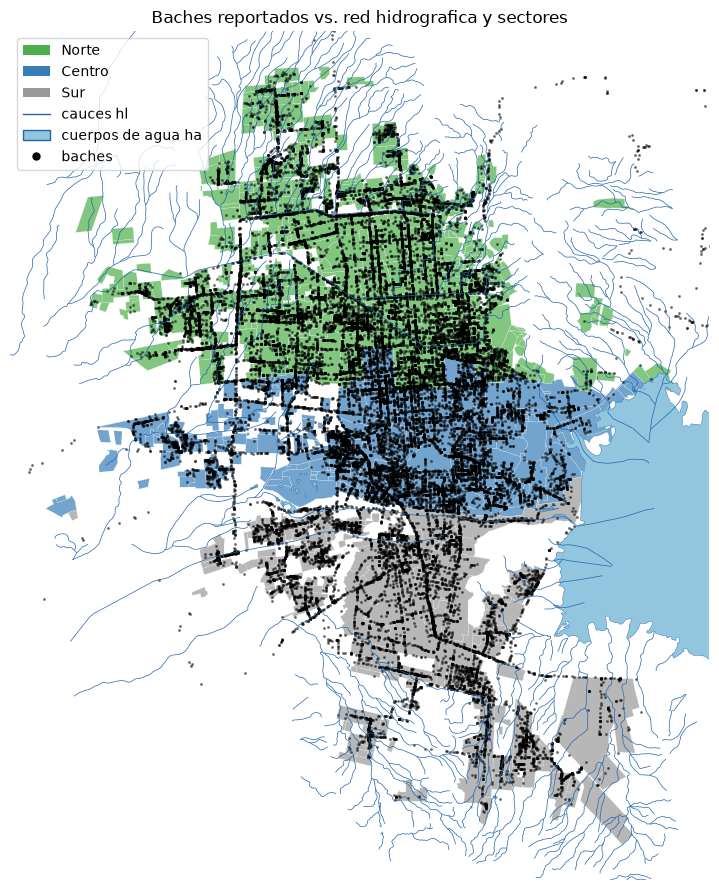

In [35]:
SUBC = DATA / "inegi/hidrografia_hermosillo/subc_hermosillo.gpkg"
hl = gpd.read_file(SUBC, layer="hl").to_crs(METRICO)
ha = gpd.read_file(SUBC, layer="ha").to_crs(METRICO)

# recorte a la ciudad con 1 km de margen
zona = colonias_ciudad.union_all().buffer(1000)
hl_ciudad = hl[hl.intersects(zona)]
ha_ciudad = ha[ha.intersects(zona)]

baches_geo = gpd.GeoDataFrame(
    baches,
    geometry=gpd.points_from_xy(baches["longitude"], baches["latitude"]),
    crs="EPSG:4326",
).to_crs(METRICO)

colores_sector = {"Norte": "#4daf4a", "Centro": "#377eb8", "Sur": "#999999"}

fig, ax = plt.subplots(figsize=(9, 9))
for s, c in colores_sector.items():
    colonias_ciudad[colonias_ciudad["sector"] == s].plot(
        ax=ax, color=c, edgecolor="white", linewidth=0.2, alpha=0.7
    )
hl_ciudad.plot(ax=ax, color="#2166ac", linewidth=0.5)
ha_ciudad.plot(ax=ax, color="#92c5de", edgecolor="#2166ac", linewidth=0.3)
baches_geo.plot(ax=ax, color="black", markersize=1.5, alpha=0.4)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(
    handles=[
        *[Patch(facecolor=c, label=s) for s, c in colores_sector.items()],
        Line2D([0], [0], color="#2166ac", linewidth=1, label="cauces hl"),
        Patch(facecolor="#92c5de", edgecolor="#2166ac", label="cuerpos de agua ha"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="black",
               markersize=5, label="baches"),
    ]
)
ax.set_title("Baches reportados vs. red hidrografica y sectores")
xmin, ymin, xmax, ymax = zona.bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Reportes por km2 y exposicion hidrografica

Densidad de reportes por sector y relacion, por colonia, entre km de cauce que la atraviesa (exposicion, igual que en nb06) y sus reportes de bache.

In [36]:
# km de cauce hl dentro de cada colonia (patron expo de nb06)
pares = gpd.sjoin(
    hl[["geometry"]], colonias_ciudad[["colonia_id", "geometry"]],
    how="inner", predicate="intersects",
)
geom_colonia = pares["colonia_id"].map(
    colonias_ciudad.set_index("colonia_id")["geometry"]
)
km_cauce = (
    pares.geometry.intersection(geom_colonia).length
    .groupby(pares["colonia_id"]).sum() / 1000
)

expo = colonias_ciudad.set_index("colonia_id")
expo["area_km2"] = expo.geometry.area / 1e6
expo["km_cauce"] = km_cauce.reindex(expo.index, fill_value=0)
expo["baches"] = con_sector["colonia_id"].value_counts()
expo["baches"] = expo["baches"].fillna(0)
expo["baches_km2"] = expo["baches"] / expo["area_km2"]

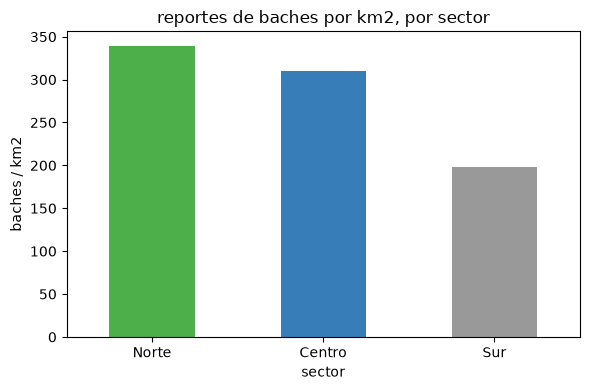

sector
Norte     339.3
Centro    310.2
Sur       197.7


In [37]:
# reportes por km2 por sector
den_baches = (
    con_sector["sector"].value_counts() / sector_area["area_km2"]
).reindex(orden_sectores)
den_baches.plot.bar(figsize=(6, 4), rot=0,
                    color=["#4daf4a", "#377eb8", "#999999"])
plt.ylabel("baches / km2")
plt.title("reportes de baches por km2, por sector")
plt.tight_layout()
plt.show()
print(den_baches.round(1).to_string())

In [68]:
# distancia de cada reporte a los 3 tramos hl mas cercanos + su orden Strahler
# (mismas 6 columnas que nb07, pero aqui el punto es el propio bache)
hl_cerca = hl[hl.intersects(colonias_ciudad.union_all().buffer(5000))].copy()
geoms = hl_cerca.geometry
orden_hl = hl_cerca["ORDER_1"].to_numpy()
sindex = hl_cerca.sindex

pts = gpd.GeoSeries(
    gpd.points_from_xy(con_sector["longitude"], con_sector["latitude"]),
    crs="EPSG:4326",
).to_crs(METRICO)

DIST = ["1er_cauce", "2do_cauce", "3er_cauce"]
ORDEN = ["orden_1er_cauce", "orden_2do_cauce", "orden_3er_cauce"]
d3 = np.empty((len(pts), 3))
o3 = np.empty((len(pts), 3))
for i, p in enumerate(pts):
    cand = list(sindex.query(p.buffer(5000), predicate="intersects"))
    if len(cand) < 3:
        cand = list(sindex.query(p.buffer(15000), predicate="intersects"))
    dist = geoms.iloc[cand].distance(p).to_numpy()
    sel = np.array(cand)[np.argsort(dist)[:3]]
    d3[i] = geoms.iloc[sel].distance(p).to_numpy()
    o3[i] = orden_hl[sel]

con_sector[DIST] = d3
con_sector[ORDEN] = pd.DataFrame(o3, index=con_sector.index).astype("Int64")
print(con_sector[DIST].describe().round(0))

# distancia del centroide de cada colonia a sus 3 cauces (para el scatter)
cent = colonias_ciudad.set_index("colonia_id").geometry.centroid
d3c = np.empty((len(cent), 3))
for i, p in enumerate(cent):
    cand = list(sindex.query(p.buffer(5000), predicate="intersects"))
    if len(cand) < 3:
        cand = list(sindex.query(p.buffer(15000), predicate="intersects"))
    dist = geoms.iloc[cand].distance(p).to_numpy()
    sel = np.array(cand)[np.argsort(dist)[:3]]
    d3c[i] = geoms.iloc[sel].distance(p).to_numpy()
expo[["d1", "d2", "d3"]] = (
    pd.DataFrame(d3c, index=cent.index, columns=["d1", "d2", "d3"])
    .reindex(expo.index)
)

       1er_cauce  2do_cauce  3er_cauce
count    38209.0    38209.0    38209.0
mean       540.0      786.0     1036.0
std        551.0      635.0      806.0
min          0.0        2.0        2.0
25%        106.0      258.0      345.0
50%        341.0      609.0      780.0
75%        810.0     1164.0     1627.0
max       2416.0     2769.0     3332.0


### Clasificacion de colonias por cercania a cauces (K-Means)

K-Means k=4 sobre las 3 distancias del centroide (`d1`, `d2`, `d3`); los clusters se reetiquetan por su distancia media: `Muy cercano` < `Cercano` < `Lejano` < `Muy lejano`. Nota: por la geografia de `hl`, el Centro concentrara las clases lejanas y el Norte las cercanas.

In [69]:
# clasificacion no supervisada: K-Means k=4 sobre las 3 distancias
from sklearn.cluster import KMeans

X = expo[["d1", "d2", "d3"]].dropna()
km = KMeans(n_clusters=4, n_init=10, random_state=42)
clusters = km.fit_predict(X)

# reetiquetar clusters por media de d1: menor distancia -> "Muy cercano"
etiquetas = ["Muy cercano", "Cercano", "Lejano", "Muy lejano"]
orden_cluster = (
    X.assign(c=clusters).groupby("c")["d1"].mean().sort_values().index
)
mapa_cluster = {c: etiquetas[i] for i, c in enumerate(orden_cluster)}
expo["cercania"] = (
    pd.Series(clusters, index=X.index).map(mapa_cluster)
    .astype(pd.CategoricalDtype(etiquetas, ordered=True))
)

print(expo["cercania"].value_counts().reindex(etiquetas).to_string())
print()
print(expo.groupby("cercania", observed=True)[["d1", "d2", "d3"]]
      .mean().round(0).to_string())

cercania
Muy cercano    417
Cercano        188
Lejano         116
Muy lejano      41

                 d1      d2      d3
cercania                           
Muy cercano   124.0   218.0   293.0
Cercano       434.0   653.0   793.0
Lejano        675.0  1018.0  1471.0
Muy lejano   1417.0  1836.0  2200.0


### Outliers por distancia al cauce (por sector)

Outlier = reporte cuya distancia al `1er_cauce` mas cercano supera Q3 + 1.5*IQR **de su sector**. Los reportes outlier se excluyen del conteo por colonia del scatter de abajo.

Norte: Q1=58 m, Q3=439 m, limite=1011 m -> 585 reportes outlier de 18857
Centro: Q1=513 m, Q3=1527 m, limite=3048 m -> 0 reportes outlier de 11452
Sur: Q1=102 m, Q3=628 m, limite=1417 m -> 257 reportes outlier de 7900

842 reportes outlier en total


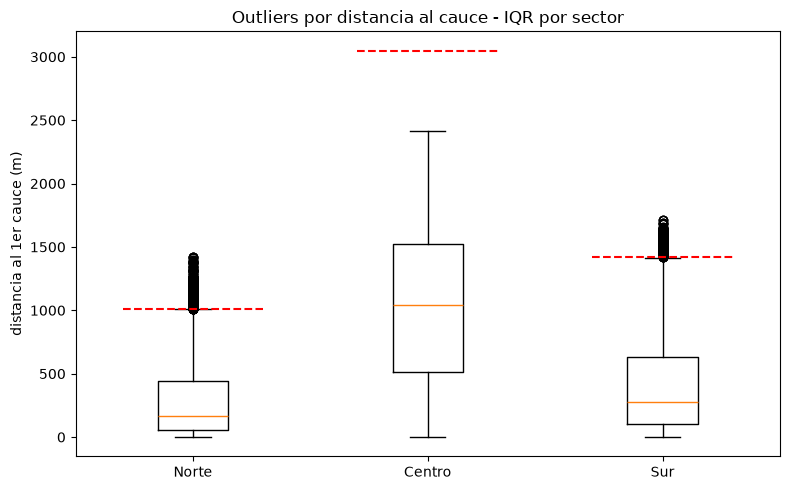

In [44]:
# outliers = reportes demasiado lejos de cualquier cauce hl
# (IQR calculado POR SECTOR sobre la distancia al 1er cauce)
con_sector["es_outlier"] = False
datos_box = []
for s in orden_sectores:
    d = con_sector.loc[con_sector["sector"] == s, "1er_cauce"].dropna()
    q1, q3 = d.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr
    con_sector.loc[d.index[d > limite], "es_outlier"] = True
    datos_box.append(d)
    print(f"{s}: Q1={q1:.0f} m, Q3={q3:.0f} m, limite={limite:.0f} m "
          f"-> {(d > limite).sum()} reportes outlier de {len(d)}")

print(f"\n{int(con_sector['es_outlier'].sum())} reportes outlier en total")

# conteo por colonia solo con reportes NO outlier
expo["baches_sinout"] = (
    con_sector.loc[~con_sector["es_outlier"], "colonia_id"]
    .value_counts().reindex(expo.index, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(datos_box, tick_labels=orden_sectores, showfliers=True)
for i, d in enumerate(datos_box):
    q3 = d.quantile(0.75)
    limite = q3 + 1.5 * (q3 - d.quantile(0.25))
    ax.hlines(limite, i + 0.7, i + 1.3, colors="red", linestyles="--")
ax.set_ylabel("distancia al 1er cauce (m)")
ax.set_title("Outliers por distancia al cauce - IQR por sector")
plt.tight_layout()
plt.show()

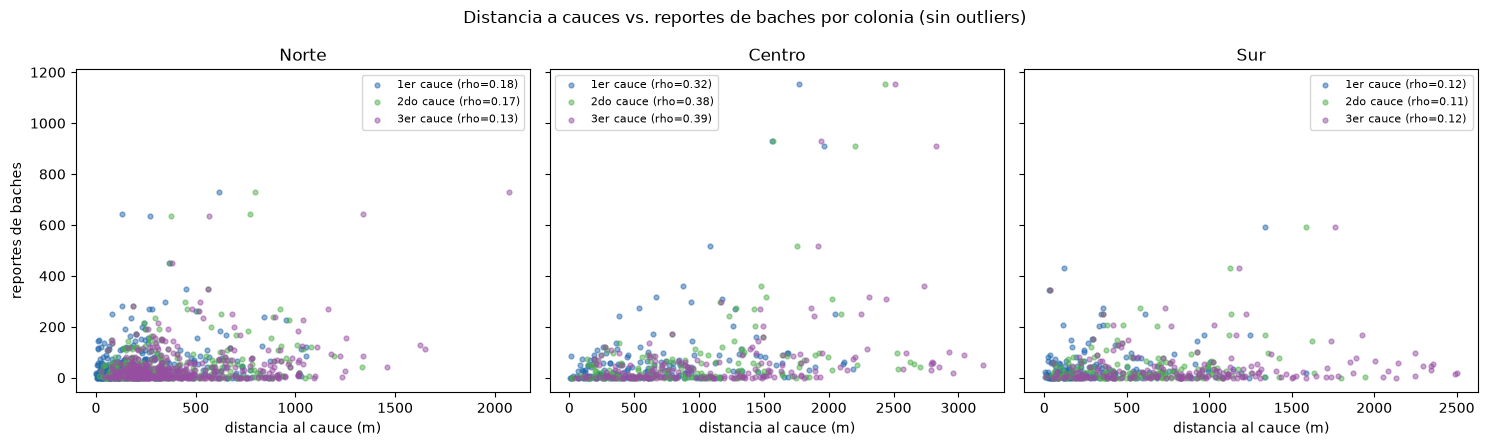

In [45]:
# distancia a cada cauce vs. reportes de baches por colonia - un panel por sector
# (un color por distancia: 1er/2do/3er cauce del centroide de la colonia)
from scipy.stats import spearmanr
COLS_CAUCE = [("d1", "1er"), ("d2", "2do"), ("d3", "3er")]
colores_cauce = {"d1": "#2166ac", "d2": "#4daf4a", "d3": "#984ea3"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, s in zip(axes, orden_sectores):
    d = expo[expo["sector"] == s].dropna(subset=["d1"])
    for col, nombre in COLS_CAUCE:
        rho = spearmanr(d[col], d["baches_sinout"]).statistic
        ax.scatter(d[col], d["baches_sinout"], s=12, alpha=0.5,
                   color=colores_cauce[col],
                   label=f"{nombre} cauce (rho={rho:.2f})")
    ax.set_title(s)
    ax.set_xlabel("distancia al cauce (m)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("reportes de baches")
fig.suptitle("Distancia a cauces vs. reportes de baches por colonia (sin outliers)")
plt.tight_layout()
plt.show()

### Mapa: reportes de bache por cercania de su colonia

¿Qué muestra el mapa?

Cada punto es un reporte de bache del bachómetro (38,209 reportes georreferenciados que cayeron dentro de una colonia con sector). El color del punto no se calcula midiendo la distancia del propio bache a un cauce, sino que hereda la clase cercania de su colonia: cada colonia fue clasificada antes con K-Means (k=4) según las distancias d1, d2, d3 de su centroide a los 3 tramos de cauce hl más cercanos, y los clusters se reetiquetaron por su distancia media:

Muy cercano — d1 media ≈124 m (417 colonias)
Cercano — ≈434 m (188)
Lejano — ≈675 m (116)
Muy lejano — ≈1,417 m (41)
¿Por qué heredar la clase de la colonia en vez de medir el punto? Porque la unidad de análisis de la libreta es la colonia: así el mapa mantiene consistencia con los conteos, tasas y correlaciones calculados por colonia, y evita que un bache aislado dentro de una colonia cercana parezca contradictorio.

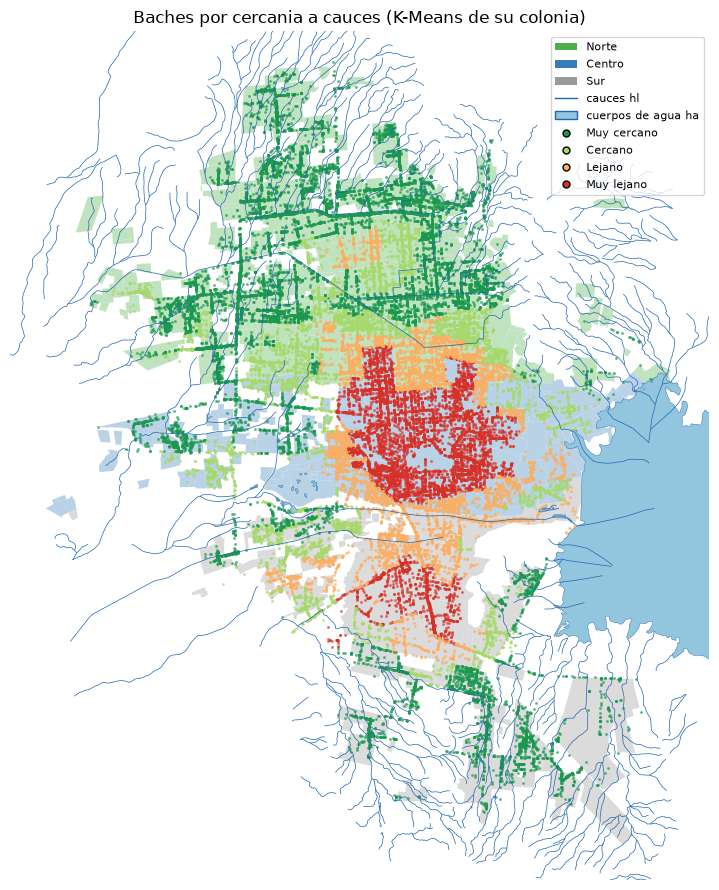

In [70]:
# cada bache hereda la cercania K-Means de su colonia
con_sector["cercania"] = con_sector["colonia_id"].map(expo["cercania"])

colores_cer = {
    "Muy cercano": "#1a9850",
    "Cercano": "#a6d96a",
    "Lejano": "#fdae61",
    "Muy lejano": "#d73027",
}
baches_cer = gpd.GeoDataFrame(
    con_sector.dropna(subset=["cercania"]),
    geometry=gpd.points_from_xy(
        con_sector.dropna(subset=["cercania"])["longitude"],
        con_sector.dropna(subset=["cercania"])["latitude"],
    ),
    crs="EPSG:4326",
).to_crs(METRICO)

fig, ax = plt.subplots(figsize=(9, 9))
for s, c in colores_sector.items():
    colonias_ciudad[colonias_ciudad["sector"] == s].plot(
        ax=ax, color=c, edgecolor="white", linewidth=0.2, alpha=0.35
    )
hl_ciudad.plot(ax=ax, color="#2166ac", linewidth=0.5)
ha_ciudad.plot(ax=ax, color="#92c5de", edgecolor="#2166ac", linewidth=0.3)
# lejanos primero para que los cercanos queden encima
for et in reversed(etiquetas):
    baches_cer[baches_cer["cercania"] == et].plot(
        ax=ax, color=colores_cer[et], markersize=1.5, alpha=0.5
    )

ax.legend(
    handles=[
        *[Patch(facecolor=c, label=s) for s, c in colores_sector.items()],
        Line2D([0], [0], color="#2166ac", linewidth=1, label="cauces hl"),
        Patch(facecolor="#92c5de", edgecolor="#2166ac",
              label="cuerpos de agua ha"),
        *[Line2D([0], [0], marker="o", color="none",
                 markerfacecolor=colores_cer[et], markersize=5, label=et)
          for et in etiquetas],
    ],
    fontsize=8,
)
ax.set_title("Baches por cercania a cauces (K-Means de su colonia)")
xmin, ymin, xmax, ymax = zona.bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()
plt.tight_layout()
plt.show()

### Proporcion de reportes por nivel de cercania

Que fraccion de los reportes cae en cada clase de cercania - primero la ciudad completa, luego dentro de cada sector.

ciudad: {'Muy cercano': 39.3, 'Cercano': 20.8, 'Lejano': 20.5, 'Muy lejano': 19.4}
cercania  Muy cercano  Cercano  Lejano  Muy lejano
sector                                            
Norte            58.8     24.7    16.5         0.0
Centro            9.0     14.1    22.5        54.5
Sur              36.8     21.2    27.1        14.9


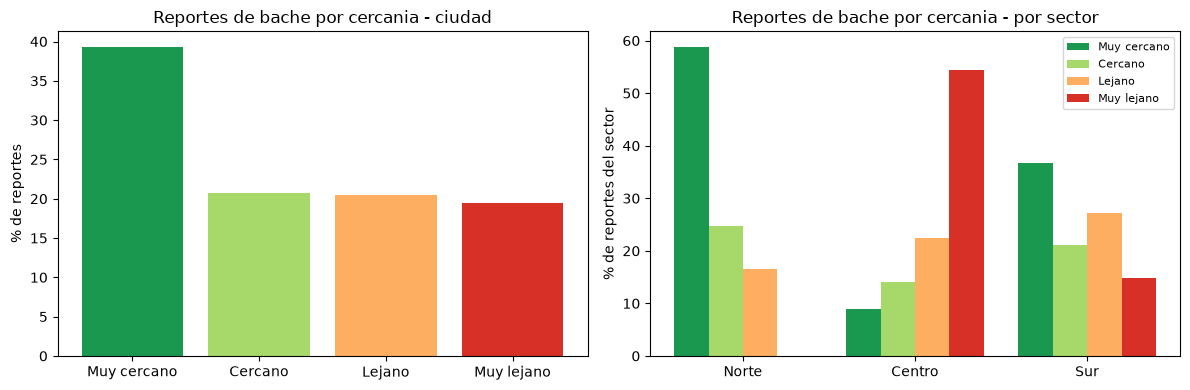

In [71]:
# proporcion de reportes por nivel de cercania
prop_ciudad = (
    con_sector["cercania"].value_counts(normalize=True)
    .reindex(etiquetas) * 100
)
prop_sector = (
    con_sector.groupby(["sector", "cercania"], observed=True).size()
    .unstack(fill_value=0)
    .reindex(index=orden_sectores, columns=etiquetas, fill_value=0)
)
prop_sector = prop_sector.div(prop_sector.sum(axis=1), axis=0) * 100
print("ciudad:", prop_ciudad.round(1).to_dict())
print(prop_sector.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(etiquetas, prop_ciudad,
            color=[colores_cer[e] for e in etiquetas])
axes[0].set_ylabel("% de reportes")
axes[0].set_title("Reportes de bache por cercania - ciudad")

x = np.arange(len(orden_sectores))
w = 0.2
for i, et in enumerate(etiquetas):
    axes[1].bar(x + (i - 1.5) * w, prop_sector[et], w,
                color=colores_cer[et], label=et)
axes[1].set_xticks(x, orden_sectores)
axes[1].set_ylabel("% de reportes del sector")
axes[1].set_title("Reportes de bache por cercania - por sector")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

tasa ciudad (rep/km2): {'Muy cercano': 113.5, 'Cercano': 59.9, 'Lejano': 59.1, 'Muy lejano': 56.0}
cercania  Muy cercano  Cercano  Lejano  Muy lejano
sector                                            
Norte           199.6     83.7    56.0         0.0
Centro           27.9     43.7    69.7       169.0
Sur              72.7     41.9    53.6        29.5


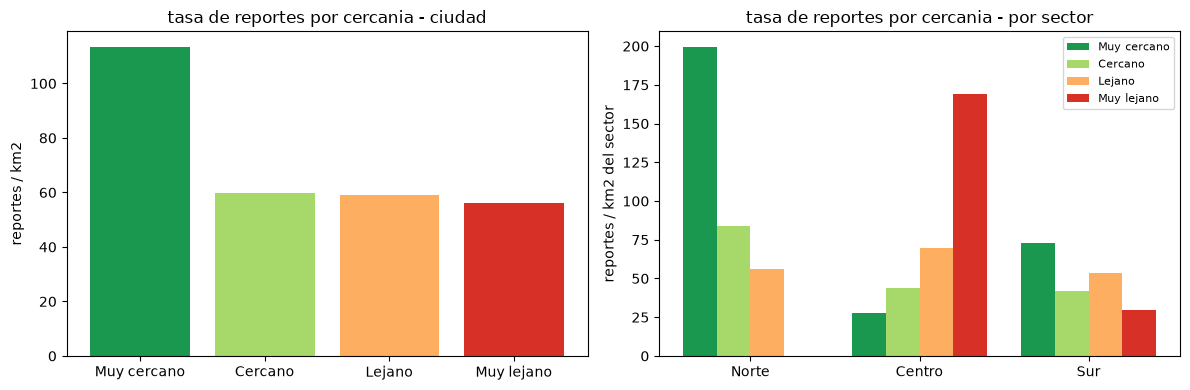

In [63]:
# tasa: reportes por clase / km2 del sector (o de la ciudad completa)
# descomposicion de la densidad por banda de cercania: las clases
# de un sector suman su densidad total
expo_s = expo[expo["sector"].notna()]

area_ciudad = sector_area["area_km2"].sum()
rep_clase = con_sector["cercania"].value_counts().reindex(etiquetas, fill_value=0)
tasa_ciudad = rep_clase / area_ciudad

rep_sc = (
    con_sector.groupby(["sector", "cercania"], observed=True).size()
    .unstack(fill_value=0)
    .reindex(index=orden_sectores, columns=etiquetas, fill_value=0)
)
tasa_sector = rep_sc.div(
    sector_area["area_km2"].reindex(orden_sectores), axis=0
)
print("tasa ciudad (rep/km2):", tasa_ciudad.round(1).to_dict())
print(tasa_sector.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(etiquetas, tasa_ciudad,
            color=[colores_cer[e] for e in etiquetas])
axes[0].set_ylabel("reportes / km2")
axes[0].set_title("tasa de reportes por cercania - ciudad")

x = np.arange(len(orden_sectores))
w = 0.2
for i, et in enumerate(etiquetas):
    axes[1].bar(x + (i - 1.5) * w, tasa_sector[et], w,
                color=colores_cer[et], label=et)
axes[1].set_xticks(x, orden_sectores)
axes[1].set_ylabel("reportes / km2 del sector")
axes[1].set_title("tasa de reportes por cercania - por sector")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

tasa N+S (rep/km2): {'Muy cercano': 146.5, 'Cercano': 66.2, 'Lejano': 55.0, 'Muy lejano': 12.3}
cercania  Muy cercano  Cercano  Lejano  Muy lejano
sector                                            
Norte           199.6     83.7    56.0         0.0
Sur              72.7     41.9    53.6        29.5


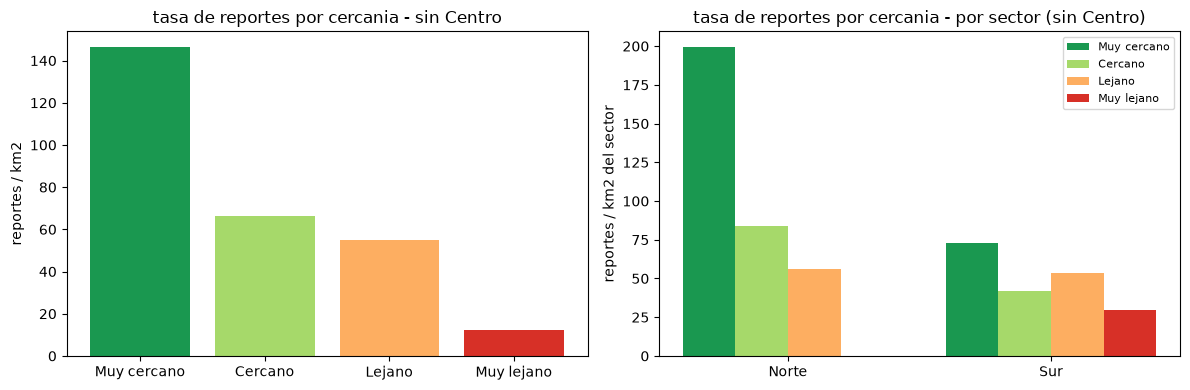

In [64]:
# misma tasa pero SIN el sector Centro - casi no tiene km de cauce
# y domina el comparativo; asi quedan comparables Norte y Sur
sectores_sc = ["Norte", "Sur"]
con_sc = con_sector[con_sector["sector"] != "Centro"]
area_ns = sector_area.loc[sectores_sc, "area_km2"].sum()

rep_clase_sc = con_sc["cercania"].value_counts().reindex(etiquetas, fill_value=0)
tasa_ciudad_sc = rep_clase_sc / area_ns

rep_sc2 = (
    con_sc.groupby(["sector", "cercania"], observed=True).size()
    .unstack(fill_value=0)
    .reindex(index=sectores_sc, columns=etiquetas, fill_value=0)
)
tasa_sector_sc = rep_sc2.div(
    sector_area["area_km2"].reindex(sectores_sc), axis=0
)
print("tasa N+S (rep/km2):", tasa_ciudad_sc.round(1).to_dict())
print(tasa_sector_sc.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(etiquetas, tasa_ciudad_sc,
            color=[colores_cer[e] for e in etiquetas])
axes[0].set_ylabel("reportes / km2")
axes[0].set_title("tasa de reportes por cercania - sin Centro")

x = np.arange(len(sectores_sc))
w = 0.2
for i, et in enumerate(etiquetas):
    axes[1].bar(x + (i - 1.5) * w, tasa_sector_sc[et], w,
                color=colores_cer[et], label=et)
axes[1].set_xticks(x, sectores_sc)
axes[1].set_ylabel("reportes / km2 del sector")
axes[1].set_title("tasa de reportes por cercania - por sector (sin Centro)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

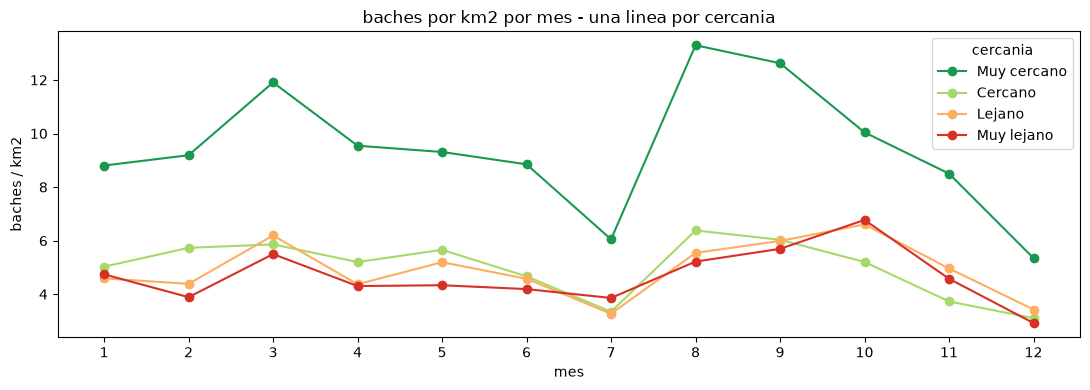

In [65]:
# baches por km2 por mes, una linea por clase de cercania
# (misma forma que la serie por año pero coloreando por clase)
mes_cer = (
    con_sector.groupby(["mes", "cercania"], observed=True).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
    .reindex(columns=etiquetas, fill_value=0)
)
tasa_mes = mes_cer / area_ciudad

fig, ax = plt.subplots(figsize=(11, 4))
for et in etiquetas:
    ax.plot(tasa_mes.index, tasa_mes[et], marker="o",
            color=colores_cer[et], label=et)
ax.set_xlabel("mes")
ax.set_ylabel("baches / km2")
ax.set_title("baches por km2 por mes - una linea por cercania")
ax.set_xticks(range(1, 13))
ax.legend(title="cercania")
plt.tight_layout()
plt.show()

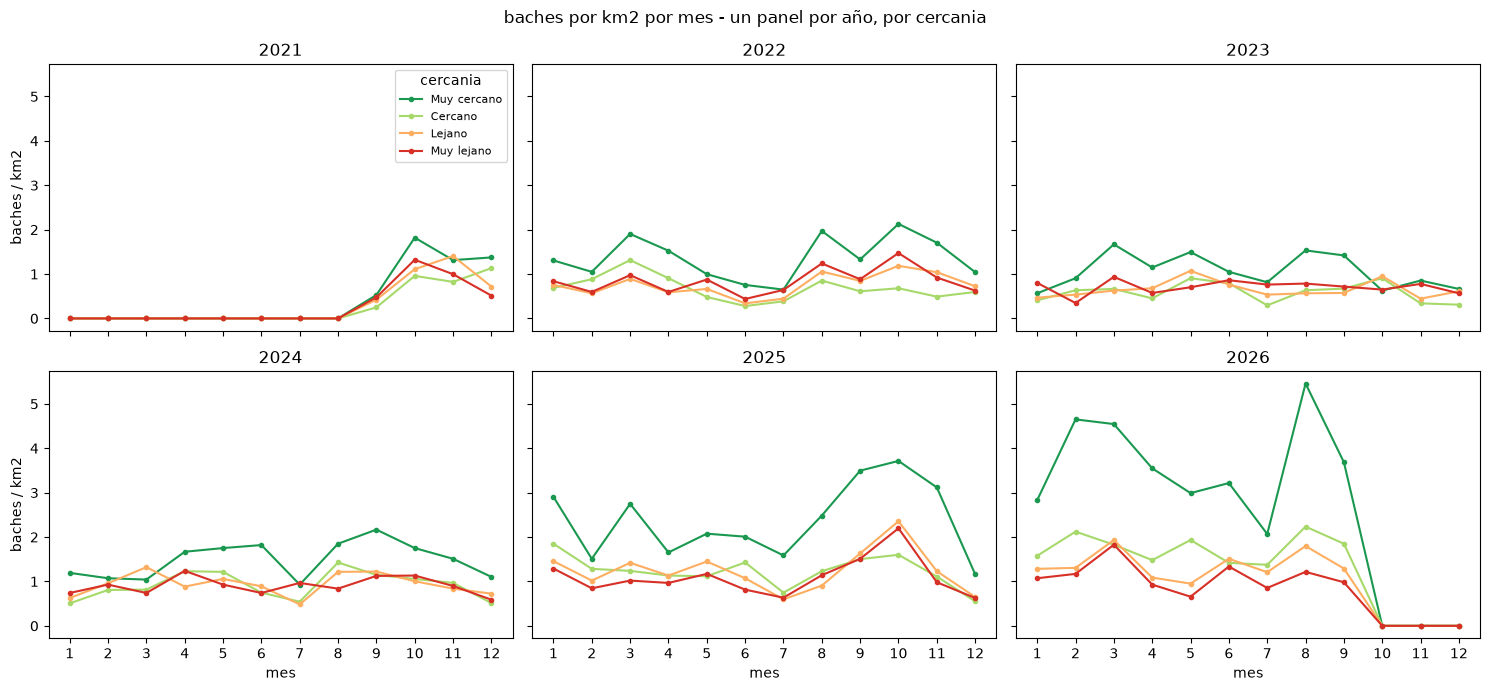

In [66]:
# baches por km2 por mes - un panel por año, lineas por clase de cercania
# 2021 solo tiene sep-dic y 2026 va hasta sep (años parciales)
mes_anio_cer = (
    con_sector.groupby(["anio", "mes", "cercania"], observed=True).size()
    .unstack(fill_value=0)
)
anios = sorted(con_sector["anio"].unique())

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, a in zip(axes.flat, anios):
    d = (
        mes_anio_cer.loc[a]
        .reindex(range(1, 13), fill_value=0)
        .reindex(columns=etiquetas, fill_value=0)
    ) / area_ciudad
    for et in etiquetas:
        ax.plot(d.index, d[et], marker="o", markersize=3,
                color=colores_cer[et], label=et)
    ax.set_title(a)
    ax.set_xticks(range(1, 13))
for ax in axes[:, 0]:
    ax.set_ylabel("baches / km2")
for ax in axes[-1]:
    ax.set_xlabel("mes")
axes[0, 0].legend(fontsize=8, title="cercania")
fig.suptitle("baches por km2 por mes - un panel por año, por cercania")
plt.tight_layout()
plt.show()

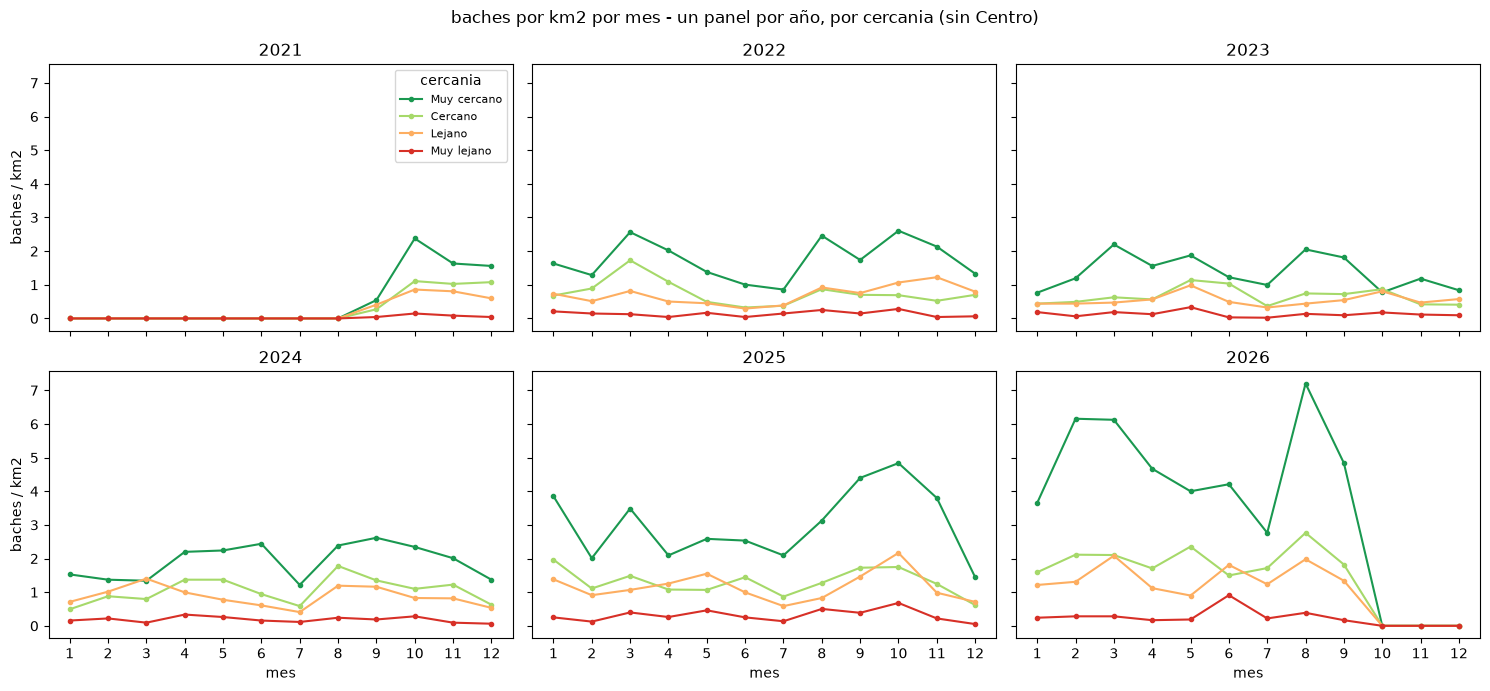

In [67]:
# mismo grid por año pero SIN el sector Centro (solo Norte + Sur)
mes_anio_cer_sc = (
    con_sc.groupby(["anio", "mes", "cercania"], observed=True).size()
    .unstack(fill_value=0)
)
anios_sc = sorted(con_sc["anio"].unique())

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
for ax, a in zip(axes.flat, anios_sc):
    d = (
        mes_anio_cer_sc.loc[a]
        .reindex(range(1, 13), fill_value=0)
        .reindex(columns=etiquetas, fill_value=0)
    ) / area_ns
    for et in etiquetas:
        ax.plot(d.index, d[et], marker="o", markersize=3,
                color=colores_cer[et], label=et)
    ax.set_title(a)
    ax.set_xticks(range(1, 13))
for ax in axes[:, 0]:
    ax.set_ylabel("baches / km2")
for ax in axes[-1]:
    ax.set_xlabel("mes")
axes[0, 0].legend(fontsize=8, title="cercania")
fig.suptitle("baches por km2 por mes - un panel por año, por cercania (sin Centro)")
plt.tight_layout()
plt.show()